<div style="background-color:black;
            color:white;
            transform:skew(-20deg);
            padding:30px;
            font-family:Verdana;
            letter-spacing:1px;
            margin:auto;
            width:fit-content;">
    <h2 style="transform:skew(20deg); margin:0;">Import Needed Libraries</h2>
</div>

In [1]:
import os
import cv2
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from sklearn.metrics import confusion_matrix , classification_report
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.optimizers import Adam , Adamax
from sklearn.utils import shuffle
from sklearn.model_selection import train_test_split
from tqdm import tqdm
import warnings
warnings.filterwarnings("ignore")

<div style="background-color:black;
            color:white;
            transform:skew(-20deg);
            padding:30px;
            font-family:Verdana;
            letter-spacing:1px;
            margin:auto;
            width:fit-content;">
    <h2 style="transform:skew(20deg); margin:0;">Reading Dataset And Get Info</h2>
</div>

#### Define Constraints

### Kaggle API Setup (Reminder)

Before proceeding, please ensure you have set your `KAGGLE_USERNAME` and `KAGGLE_KEY` in Colab secrets as described previously. If you haven't, please follow the steps:

1.  **Generate Kaggle API Token**: Go to your Kaggle account page (Profile -> Account), scroll down to the 'API' section, and click 'Create New API Token'. This will download a `kaggle.json` file.
2.  **Upload `kaggle.json` to Colab Secrets**:
    *   In Colab, click on the '🔑' (Secrets) icon on the left sidebar.
    *   Click 'Add new secret'.
    *   For the 'Name' field, type `KAGGLE_USERNAME` and for 'Value', open your `kaggle.json` file and copy the value associated with the key `username`. Then click 'Save secret'.
    *   Repeat this process for `KAGGLE_KEY`, copying the value associated with `key` from `kaggle.json`.
3.  **Enable access to `KAGGLE_USERNAME` and `KAGGLE_KEY`** for this notebook by toggling the switch next to them in the Secrets panel.

In [2]:
# Install the Kaggle library
!pip install kaggle

In [3]:
# Import necessary libraries
import os
from google.colab import userdata

# Set Kaggle API credentials from Colab secrets
os.environ['KAGGLE_USERNAME'] = userdata.get('KAGGLE_USERNAME')
os.environ['KAGGLE_KEY'] = userdata.get('KAGGLE_KEY')

# Verify if the credentials are set (optional, for debugging)
print("KAGGLE_USERNAME set.")
print("KAGGL_KEY set.")

KAGGLE_USERNAME set.
KAGGL_KEY set.


Now, let's download the correct dataset: `gunavenkatdoddi/eye-diseases-classification`.

In [4]:
# Create a directory for Kaggle datasets if it doesn't exist
!mkdir -p /content/kaggle_data

# Download the dataset from Kaggle
# The dataset name format is 'kaggle_username/dataset_name'
!kaggle datasets download -d gunavenkatdoddi/eye-diseases-classification -p /content/kaggle_data

Dataset URL: https://www.kaggle.com/datasets/gunavenkatdoddi/eye-diseases-classification
License(s): ODbL-1.0
100% 736M/736M [00:10<00:00, 70.9MB/s]



In [5]:
# Unzip the dataset. It will extract into '/content/kaggle_data/dataset'
!unzip -q /content/kaggle_data/eye-diseases-classification.zip -d /content/kaggle_data

# List the contents to verify
print("Contents of /content/kaggle_data:")
!ls -R /content/kaggle_data

Contents of /content/kaggle_data:
/content/kaggle_data:
dataset  eye-diseases-classification.zip

/content/kaggle_data/dataset:
cataract  diabetic_retinopathy	glaucoma  normal

/content/kaggle_data/dataset/cataract:
_0_4015166.jpg	  2113_left.jpg     _244_5451565.jpg  _390_5561281.jpg
0_left.jpg	  2113_right.jpg    _245_498355.jpg   _391_2115124.jpg
_100_334408.jpg   2114_left.jpg     _245_5686342.jpg  _391_3026815.jpg
_101_5139882.jpg  2114_right.jpg    _245_789720.jpg   _392_3084035.jpg
_101_709333.jpg   2115_right.jpg    _24_6096407.jpg   _392_7918570.jpg
_102_1024926.jpg  2116_left.jpg     _246_8777337.jpg  _393_746807.jpg
_102_3990401.jpg  2116_right.jpg    _247_7009710.jpg  _394_1321417.jpg
_10_3215668.jpg   2117_left.jpg     _247_9509040.jpg  _394_4972049.jpg
_103_5897328.jpg  2118_right.jpg    _248_3607543.jpg  _395_8303850.jpg
103_left.jpg	  _211_9288352.jpg  _24_8522038.jpg   _396_4783302.jpg
_104_4607170.jpg  2119_right.jpg    _248_8765348.jpg  _396_6097231.jpg
_105_5646774.

In [6]:
IMAGE_SIZE = (224,224)
BATCH_SIZE = 32
CHANNELS = 3

#### Load The Data

In [7]:
DATASET_PATH = '/content/kaggle_data/dataset'
Class_Names = os.listdir(DATASET_PATH)
Class_Names_Dict = {name:idx for idx,name in enumerate(Class_Names)}
print(Class_Names_Dict)

{'glaucoma': 0, 'normal': 1, 'cataract': 2, 'diabetic_retinopathy': 3}


In [8]:
def Load_Data():
    Images = []
    Labels = []

    for folder in os.listdir(DATASET_PATH):
        print(f"Load Images from {folder} File")
        for file in tqdm(os.listdir(os.path.join(DATASET_PATH,folder))):
            image_path = os.path.join(os.path.join(DATASET_PATH,folder),file)
            image = cv2.imread(image_path)
            image = cv2.resize(image , IMAGE_SIZE)
            image = cv2.cvtColor(image , cv2.COLOR_BGR2RGB)

            Images.append(image)
            Labels.append(Class_Names_Dict[folder])


    Images = np.array(Images , dtype='float32')
    Labels = np.array(Labels , dtype='int32')

    return (Images , Labels)

Images , Labels = Load_Data()

Load Images from glaucoma File


100%|██████████| 1007/1007 [00:10<00:00, 100.62it/s]


Load Images from normal File


100%|██████████| 1074/1074 [00:02<00:00, 517.63it/s]


Load Images from cataract File


100%|██████████| 1038/1038 [00:09<00:00, 106.46it/s]


Load Images from diabetic_retinopathy File


100%|██████████| 1098/1098 [00:02<00:00, 508.26it/s]


#### Shuffle The Images

In [9]:
Images , Labels = shuffle(Images , Labels , random_state=42)

<div style="background-color:black;
            color:white;
            transform:skew(-20deg);
            padding:30px;
            font-family:Verdana;
            letter-spacing:1px;
            margin:auto;
            width:fit-content;">
    <h2 style="transform:skew(20deg); margin:0;">EDA of Images and Get Insights</h2>
</div>

#### Number of Images

In [10]:
print(f"Number of Total Images {Images.shape[0]}")
print(f"Size of Images {IMAGE_SIZE}")

Number of Total Images 4217
Size of Images (224, 224)


In [11]:
Train_Images , dummy_Images , Train_Labels , dummy_Labels = train_test_split(Images , Labels , test_size=0.3, random_state=42, stratify=Labels)
Val_Images , Test_Images , Val_Labels , Test_Labels = train_test_split(dummy_Images , dummy_Labels , test_size=0.5, random_state=42, stratify=dummy_Labels)

In [12]:
print(f"Number of Train Images {Train_Images.shape}")
print(f"Number of Train Labels {Train_Labels.shape}")
print(f"Number of Validation Images {Val_Images.shape}")
print(f"Number of Validation Labels {Val_Labels.shape}")
print(f"Number of Test Images {Test_Images.shape}")
print(f"Number of Test Labels {Test_Labels.shape}")

Number of Train Images (2951, 224, 224, 3)
Number of Train Labels (2951,)
Number of Validation Images (633, 224, 224, 3)
Number of Validation Labels (633,)
Number of Test Images (633, 224, 224, 3)
Number of Test Labels (633,)


In [13]:
_ , train_counts = np.unique(Train_Labels , return_counts=True)
_ , val_counts = np.unique(Val_Labels , return_counts=True)
_ , test_counts = np.unique(Test_Labels , return_counts=True)

df = pd.DataFrame({
    'Train': train_counts,'Validation': val_counts, 'Test': test_counts
}, index=Class_Names)

df

,Train,Validation,Test
glaucoma,705,151,151
normal,752,161,161
cataract,726,156,156
diabetic_retinopathy,768,165,165


<Figure size 1000x600 with 0 Axes>

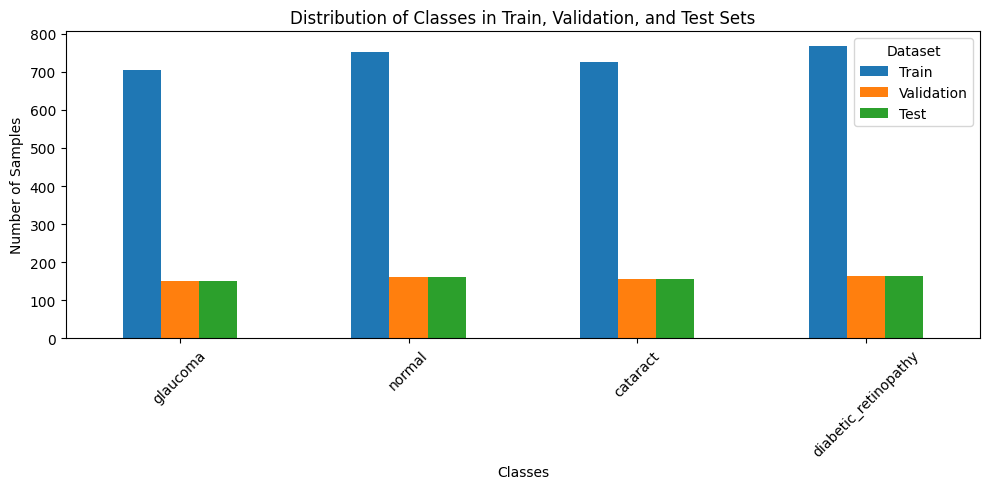

In [14]:
plt.figure(figsize=(10, 6))
df.plot(kind='bar',figsize=(10,5))
plt.title('Distribution of Classes in Train, Validation, and Test Sets')
plt.xlabel('Classes')
plt.ylabel('Number of Samples')
plt.xticks(rotation=45)
plt.legend(title='Dataset')
plt.tight_layout()
plt.show()

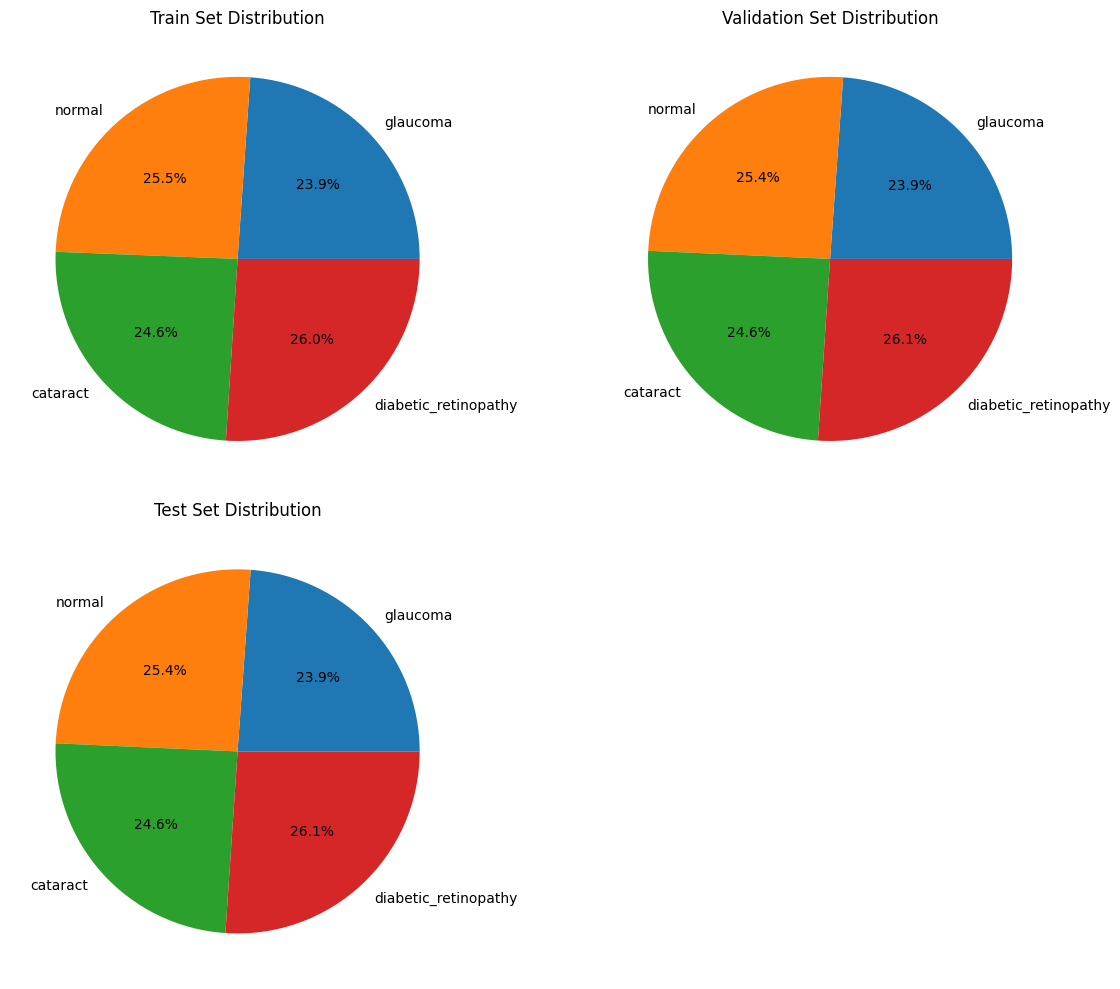

In [15]:
fig, axs = plt.subplots(2, 2, figsize=(12, 10))

df.plot.pie(y='Train', autopct='%1.1f%%', title='Train Set Distribution', ax=axs[0,0], legend=False, ylabel='')
df.plot.pie(y='Validation', autopct='%1.1f%%', title='Validation Set Distribution', ax=axs[0,1], legend=False, ylabel='')
df.plot.pie(y='Test', autopct='%1.1f%%', title='Test Set Distribution', ax=axs[1,0], legend=False, ylabel='')

axs[1,1].axis('off')

plt.tight_layout()
plt.show()

#### Images In Dataset

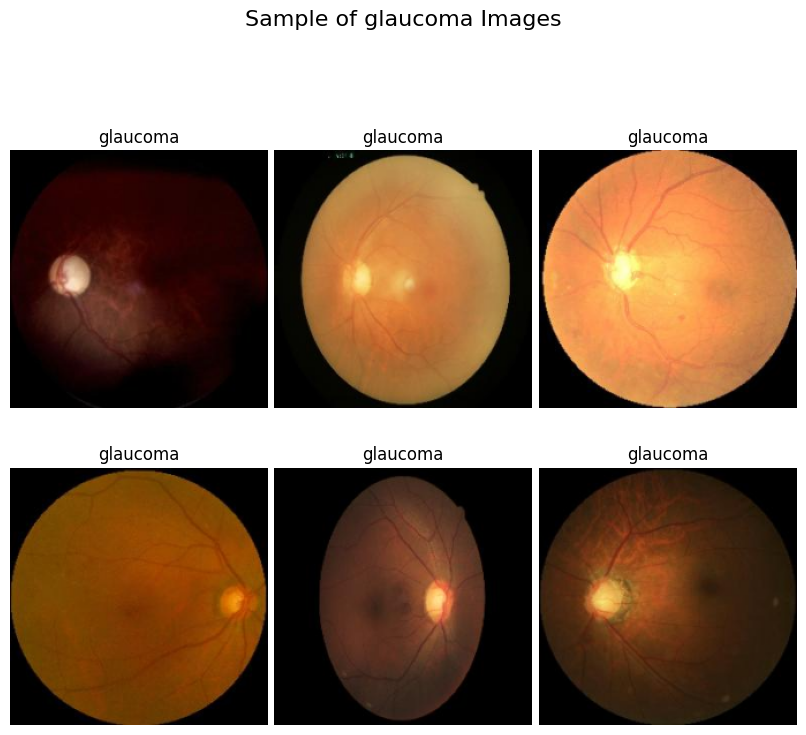

In [16]:
plt.figure(figsize=(8, 8))
plt.suptitle(f'Sample of {Class_Names[0]} Images', fontsize=16)

for i in range(6):
    plt.subplot(2, 3, i + 1)
    Category_List = np.where(Labels == 0)[0]
    idx = np.random.choice(Category_List)
    plt.imshow(Images[idx] / 255.0)
    plt.axis('off')  # Hide axis for cleaner look
    plt.title(f'{Class_Names[0]}')

plt.tight_layout(pad=0.5)
plt.subplots_adjust(top=0.88)  # Adjust top to fit the suptitle
plt.show()

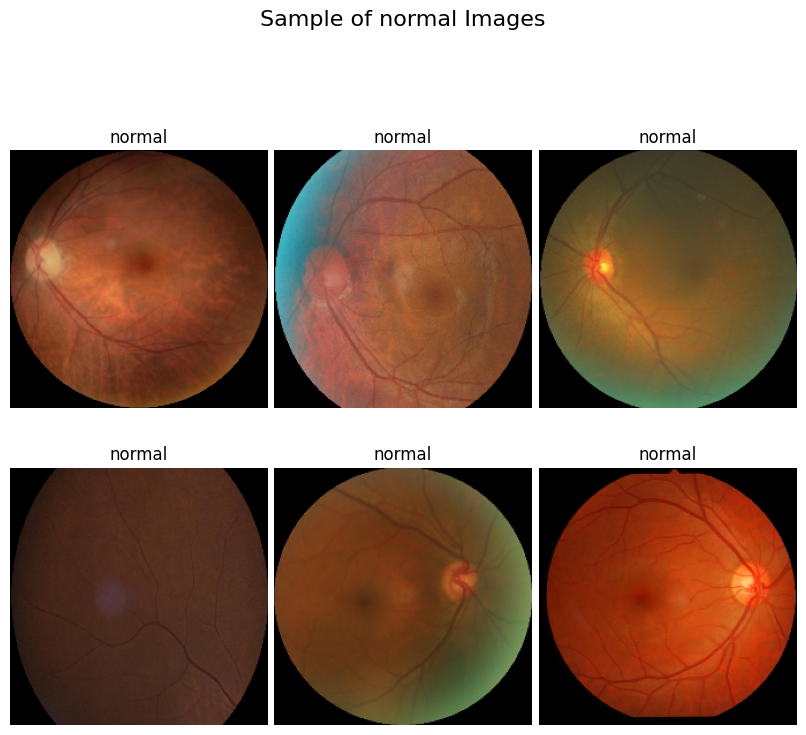

In [17]:
plt.figure(figsize=(8, 8))
plt.suptitle(f'Sample of {Class_Names[1]} Images', fontsize=16)

for i in range(6):
    plt.subplot(2, 3, i + 1)
    Category_List = np.where(Labels == 1)[0]
    idx = np.random.choice(Category_List)
    plt.imshow(Images[idx] / 255.0)
    plt.axis('off')
    plt.title(f'{Class_Names[1]}')

plt.tight_layout(pad=0.5)
plt.subplots_adjust(top=0.88)
plt.show()

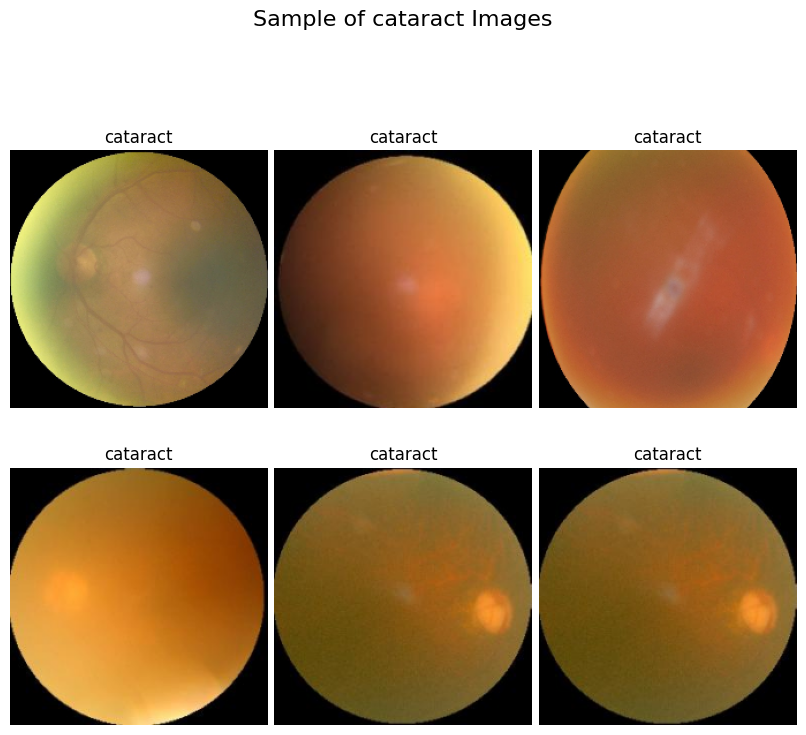

In [18]:
plt.figure(figsize=(8, 8))
plt.suptitle(f'Sample of {Class_Names[2]} Images', fontsize=16)

for i in range(6):
    plt.subplot(2, 3, i + 1)
    Category_List = np.where(Labels == 2)[0]
    idx = np.random.choice(Category_List)
    plt.imshow(Images[idx] / 255.0)
    plt.axis('off')
    plt.title(f'{Class_Names[2]}')

plt.tight_layout(pad=0.5)
plt.subplots_adjust(top=0.88)
plt.show()

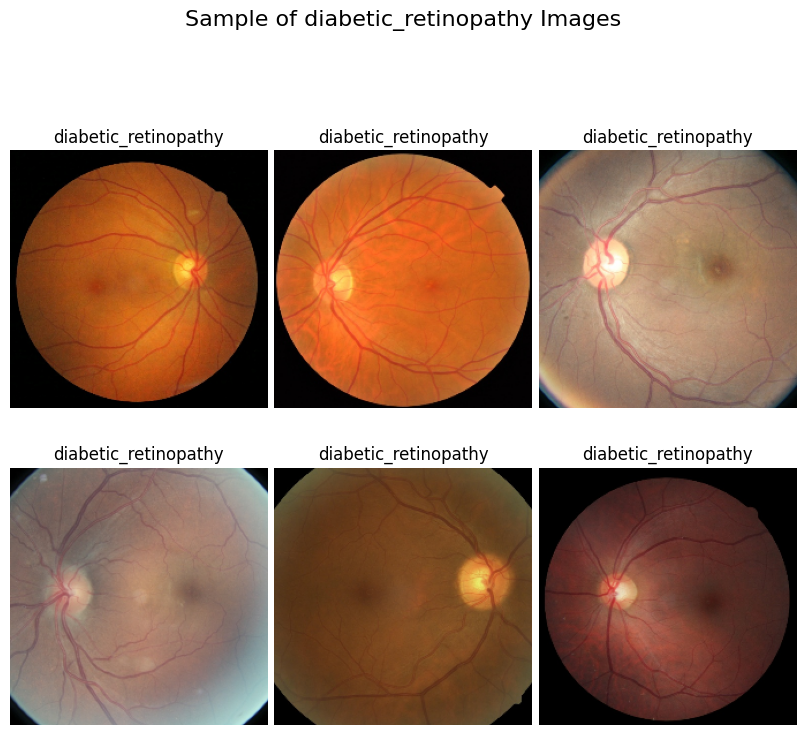

In [19]:
plt.figure(figsize=(8, 8))
plt.suptitle(f'Sample of {Class_Names[3]} Images', fontsize=16)

for i in range(6):
    plt.subplot(2, 3, i + 1)
    Category_List = np.where(Labels == 3)[0]
    idx = np.random.choice(Category_List)
    plt.imshow(Images[idx] / 255.0)
    plt.axis('off')
    plt.title(f'{Class_Names[3]}')

plt.tight_layout(pad=0.5)
plt.subplots_adjust(top=0.88)
plt.show()

<div style="background-color:black;
            color:white;
            transform:skew(-20deg);
            padding:30px;
            font-family:Verdana;
            letter-spacing:1px;
            margin:auto;
            width:fit-content;">
    <h2 style="transform:skew(20deg); margin:0;">Model Custom CNN</h2>
</div>

#### Build Custom CNN

In [20]:
train_datagen = ImageDataGenerator(rescale=1./255,
                                   rotation_range = 40,
                                   horizontal_flip = True,
                                   )

val_datagen = ImageDataGenerator(rescale=1./255)
test_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow(x=Train_Images,
    y=Train_Labels,
    batch_size=BATCH_SIZE,
    shuffle=True,
)

val_generator = val_datagen.flow(x=Val_Images,
    y=Val_Labels,
    batch_size=BATCH_SIZE,
    shuffle=True,
)

test_generator = test_datagen.flow(x=Test_Images,
    y=Test_Labels,
    batch_size=BATCH_SIZE,
    shuffle=False,
)

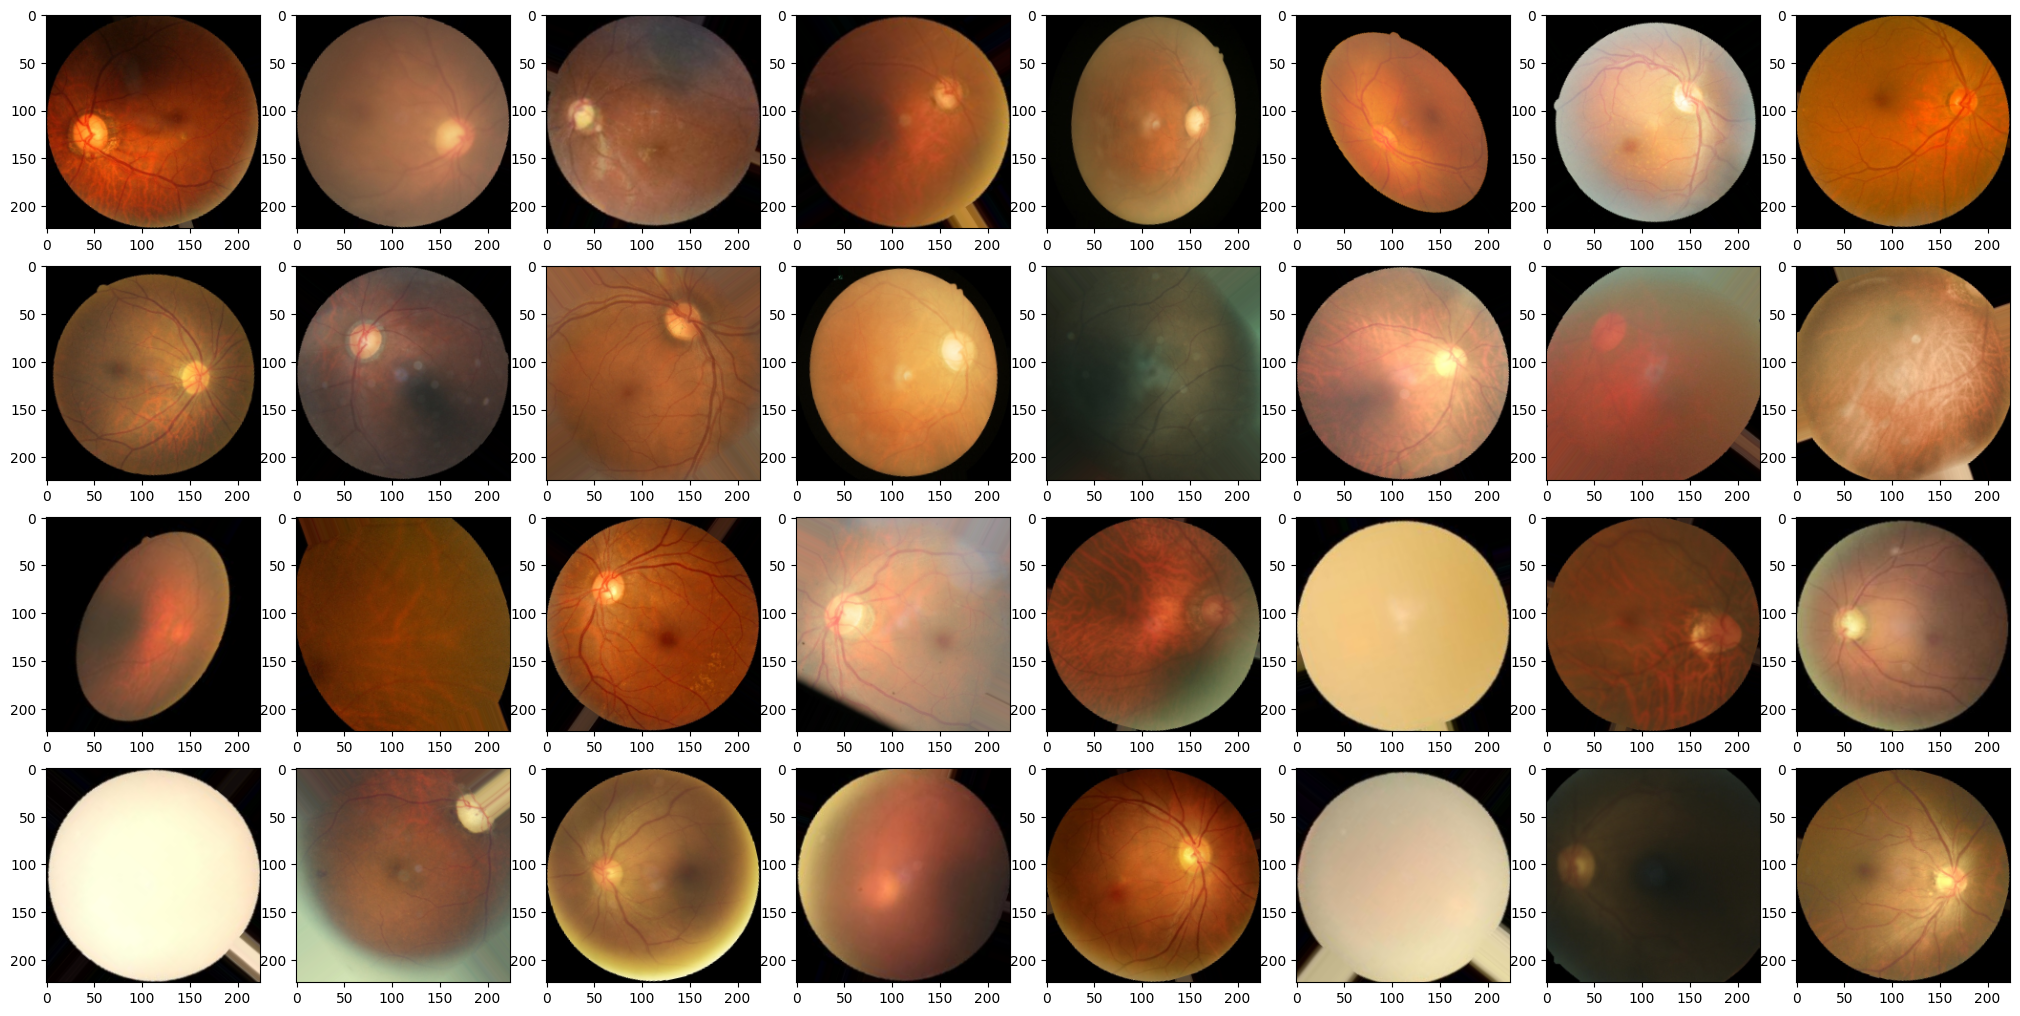

In [21]:
for x , y in train_generator:
    plt.figure(figsize=(20,20))
    for i in range(32):
        plt.subplot(8,8,i+1)
        plt.imshow(x[i])
        plt.tight_layout(pad=0 , h_pad=0 , w_pad=0)
    break

In [22]:
KerasModel = keras.models.Sequential([
    keras.layers.Conv2D(32, (3, 3), activation='relu', padding='same', input_shape=(IMAGE_SIZE[0], IMAGE_SIZE[1], CHANNELS)),
    keras.layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    keras.layers.MaxPooling2D((2, 2)),

    keras.layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    keras.layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    keras.layers.MaxPooling2D((2, 2)),

    keras.layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
    keras.layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
    keras.layers.MaxPooling2D((2, 2)),

    keras.layers.Conv2D(256, (3, 3), activation='relu', padding='same'),

    keras.layers.Flatten(),
    keras.layers.Dense(512, activation='relu'),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(4, activation='softmax', dtype='float32') # Added dtype='float32' for mixed precision stability
])

In [23]:
KerasModel.compile(optimizer=Adam(learning_rate=0.001),loss='sparse_categorical_crossentropy',metrics=['accuracy'])

In [24]:
best_model_callback = keras.callbacks.ModelCheckpoint('best_model.h5', save_best_only=True, monitor='val_loss', mode='min')
early_stopping_callback = keras.callbacks.EarlyStopping(patience=10, restore_best_weights=True)
learning_rate_reduction = keras.callbacks.ReduceLROnPlateau(monitor='val_accuracy', # Changed from val_acc to val_accuracy
                                            patience=2,
                                            verbose=1,
                                            factor=0.5,
                                            min_lr=0.00001,
                                            mode='max')

history = KerasModel.fit(
    train_generator,
    epochs=200,
    validation_data=val_generator,
    callbacks=[
        early_stopping_callback,
        best_model_callback,
        learning_rate_reduction
    ])

Epoch 1/200
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 506ms/step - accuracy: 0.3607 - loss: 1.3567

93/93 ━━━━━━━━━━━━━━━━━━━━ 118s 1s/step - accuracy: 0.4456 - loss: 1.1811 - val_accuracy: 0.5197 - val_loss: 0.9907 - learning_rate: 0.0010
Epoch 2/200
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 410ms/step - accuracy: 0.6015 - loss: 0.8571

93/93 ━━━━━━━━━━━━━━━━━━━━ 90s 972ms/step - accuracy: 0.6049 - loss: 0.8593 - val_accuracy: 0.6493 - val_loss: 0.8135 - learning_rate: 0.0010
Epoch 3/200
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 406ms/step - accuracy: 0.6571 - loss: 0.7770

93/93 ━━━━━━━━━━━━━━━━━━━━ 131s 1s/step - accuracy: 0.6760 - loss: 0.7424 - val_accuracy: 0.7125 - val_loss: 0.7318 - learning_rate: 0.0010
Epoch 4/200
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 414ms/step - accuracy: 0.7248 - loss: 0.6740

93/93 ━━━━━━━━━━━━━━━━━━━━ 138s 1s/step - accuracy: 0.7279 - loss: 0.6409 - val_accuracy: 0.7567 - val_loss: 0.6000 - learning_rate: 0.0010
Epoch 5/200
93/93 ━━━━━━━━━━━━━━━━━━━━ 39s 420ms/step - accuracy: 0.7658 - loss: 0.5693 - val_accuracy: 0.7599 - val_loss: 0.6261 - learning_rate: 0.0010
Epoch 6/200
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 401ms/step - accuracy: 0.7761 - loss: 0.5631

...

93/93 ━━━━━━━━━━━━━━━━━━━━ 150s 2s/step - accuracy: 0.8712 - loss: 0.3173 - val_accuracy: 0.8515 - val_loss: 0.3669 - learning_rate: 2.5000e-04
Epoch 19/200
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 405ms/step - accuracy: 0.8825 - loss: 0.3013

93/93 ━━━━━━━━━━━━━━━━━━━━ 144s 2s/step - accuracy: 0.8780 - loss: 0.3046 - val_accuracy: 0.8468 - val_loss: 0.3653 - learning_rate: 2.5000e-04
Epoch 20/200
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 401ms/step - accuracy: 0.8760 - loss: 0.3201


Epoch 20: ReduceLROnPlateau reducing learning rate to 0.0001250000059371814.
93/93 ━━━━━━━━━━━━━━━━━━━━ 148s 2s/step - accuracy: 0.8658 - loss: 0.3226 - val_accuracy: 0.8468 - val_loss: 0.3610 - learning_rate: 2.5000e-04
Epoch 21/200
93/93 ━━━━━━━━━━━━━━━━━━━━ 40s 433ms/step - accuracy: 0.8821 - loss: 0.2902 - val_accuracy: 0.8531 - val_loss: 0.3682 - learning_rate: 1.2500e-04
Epoch 22/200
93/93 ━━━━━━━━━━━━━━━━━━━━ 39s 418ms/step - accuracy: 0.8821 - loss: 0.2916 - val_accuracy: 0.8594 - val_loss: 0.3675 - learning_rate: 1.2500e-04
Epoch 23/200
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 403ms/step - accuracy: 0.8868 - loss: 0.2789

93/93 ━━━━━━━━━━━━━━━━━━━━ 137s 1s/step - accuracy: 0.8882 - loss: 0.2850 - val_accuracy: 0.8531 - val_loss: 0.3552 - learning_rate: 1.2500e-04
Epoch 24/200
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 411ms/step - accuracy: 0.8955 - loss: 0.2709
Epoch 24: ReduceLROnPlateau reducing learning rate to 6.25000029685907e-05.
93/93 ━━━━━━━━━━━━━━━━━━━━ 40s 421ms/step - accuracy: 0.8861 - loss: 0.2873 - val_accuracy: 0.8562 - val_loss: 0.3557 - learning_rate: 1.2500e-04
Epoch 25/200
93/93 ━━━━━━━━━━━━━━━━━━━━ 39s 417ms/step - accuracy: 0.8868 - loss: 0.2822 - val_accuracy: 0.8594 - val_loss: 0.3653 - learning_rate: 6.2500e-05
Epoch 26/200
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 403ms/step - accuracy: 0.8969 - loss: 0.2726
Epoch 26: ReduceLROnPlateau reducing learning rate to 3.125000148429535e-05.
93/93 ━━━━━━━━━━━━━━━━━━━━ 39s 417ms/step - accuracy: 0.8922 - loss: 0.2751 - val_accuracy: 0.8468 - val_loss: 0.3696 - learning_rate: 6.2500e-05
Epoch 27/200
93/93 ━━━━━━━━━━━━━━━━━━━━ 38s 411ms/step - accuracy: 0.8902 - 

93/93 ━━━━━━━━━━━━━━━━━━━━ 147s 2s/step - accuracy: 0.8936 - loss: 0.2746 - val_accuracy: 0.8578 - val_loss: 0.3514 - learning_rate: 3.1250e-05
Epoch 29/200
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 409ms/step - accuracy: 0.8940 - loss: 0.2694
Epoch 29: ReduceLROnPlateau reducing learning rate to 1.5625000742147677e-05.
93/93 ━━━━━━━━━━━━━━━━━━━━ 39s 418ms/step - accuracy: 0.8946 - loss: 0.2645 - val_accuracy: 0.8610 - val_loss: 0.3522 - learning_rate: 3.1250e-05
Epoch 30/200
93/93 ━━━━━━━━━━━━━━━━━━━━ 39s 422ms/step - accuracy: 0.8960 - loss: 0.2654 - val_accuracy: 0.8594 - val_loss: 0.3537 - learning_rate: 1.5625e-05
Epoch 31/200
93/93 ━━━━━━━━━━━━━━━━━━━━ 0s 407ms/step - accuracy: 0.8904 - loss: 0.2702
Epoch 31: ReduceLROnPlateau reducing learning rate to 1e-05.
93/93 ━━━━━━━━━━━━━━━━━━━━ 39s 416ms/step - accuracy: 0.8939 - loss: 0.2748 - val_accuracy: 0.8610 - val_loss: 0.3536 - learning_rate: 1.5625e-05
Epoch 32/200
93/93 ━━━━━━━━━━━━━━━━━━━━ 39s 418ms/step - accuracy: 0.8963 - loss: 0.2640 -

#### Summary of KerasModel


In [25]:
print(KerasModel.summary())

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 224, 224, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 112, 112, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 56, 56, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 200704)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │   102,760,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         2,052 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 310,035,566 (1.15 GB)

 Trainable params: 103,345,188 (394.23 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 206,690,378 (788.46 MB)

None


<div style="background-color:black;
            color:white;
            transform:skew(-20deg);
            padding:30px;
            font-family:Verdana;
            letter-spacing:1px;
            margin:auto;
            width:fit-content;">
    <h2 style="transform:skew(20deg); margin:0;">Evaluate Custom CNN</h2>
</div>

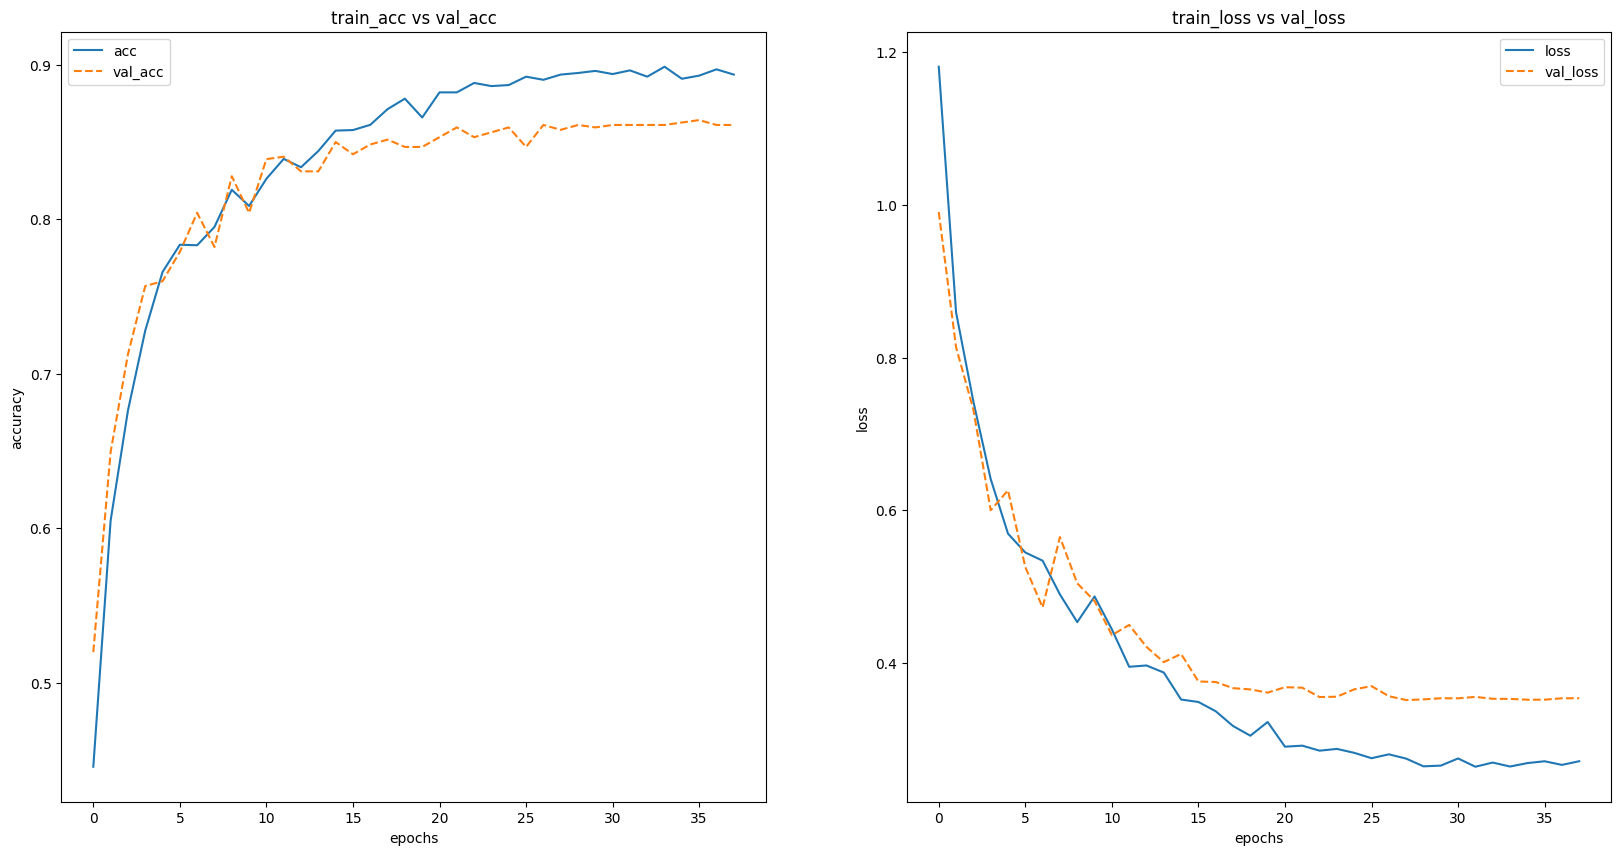

In [26]:
def plot_accuracy_loss(history):
    """
        Plot the accuracy and the loss during the training of the nn.
    """
    fig = plt.figure(figsize=(20,10))

    # Plot accuracy
    plt.subplot(121)
    plt.plot(history.history['accuracy'],'-', label = "acc")
    plt.plot(history.history['val_accuracy'], '--', label = "val_acc")
    plt.title("train_acc vs val_acc")
    plt.ylabel("accuracy")
    plt.xlabel("epochs")
    plt.legend()

    # Plot loss function
    plt.subplot(122)
    plt.plot(history.history['loss'],'-', label = "loss")
    plt.plot(history.history['val_loss'], '--', label = "val_loss")
    plt.title("train_loss vs val_loss")
    plt.ylabel("loss")
    plt.xlabel("epochs")

    plt.legend()
    plt.show()
plot_accuracy_loss(history)

In [27]:
model = keras.models.load_model('best_model.h5')
predictions = model.predict(test_generator)     # Vector of probabilities
pred_labels = np.argmax(predictions, axis = 1) # We take the highest probability

20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 67ms/step


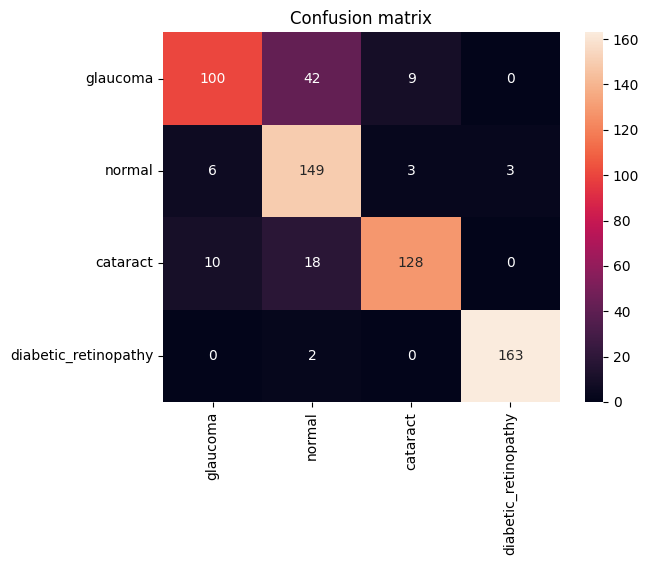

In [28]:
CM = confusion_matrix(Test_Labels, pred_labels)
ax = plt.axes()
sns.heatmap(CM, annot=True,
           annot_kws={"size": 10},
           xticklabels = Class_Names,
           yticklabels = Class_Names,
           ax = ax,
           fmt='d')
ax.set_title('Confusion matrix')
plt.show()

In [29]:
print(classification_report(Test_Labels, pred_labels,target_names = Class_Names))

                      precision    recall  f1-score   support

            glaucoma       0.86      0.66      0.75       151
              normal       0.71      0.93      0.80       161
            cataract       0.91      0.82      0.86       156
diabetic_retinopathy       0.98      0.99      0.98       165

            accuracy                           0.85       633
           macro avg       0.87      0.85      0.85       633
        weighted avg       0.87      0.85      0.85       633



<div style="background-color:black;
            color:white;
            transform:skew(-20deg);
            padding:30px;
            font-family:Verdana;
            letter-spacing:1px;
            margin:auto;
            width:fit-content;">
    <h2 style="transform:skew(20deg); margin:0;">Predicting with Custom CNN</h2>
</div>

In [1]:
plt.figure(figsize=(15,20))
plt.suptitle(f"Sample Of Images Predicted by KerasModel" , fontsize=16)

for i in range(24):
    plt.subplot(6,5,i+1)
    idx = np.random.choice(np.arange(len(pred_labels)))
    plt.imshow(Test_Images[idx] / 255.0)
    plt.xlabel(f'Pred {Class_Names[pred_labels[idx]]}')
    plt.ylabel(f'True {Class_Names[Test_Labels[idx]]}')
    plt.tight_layout(pad=0 , h_pad=0 , w_pad=2)

NameError: name 'plt' is not defined

### Download Custom CNN Model

In [31]:
# To download the custom CNN model file (.h5) to your local machine:
from google.colab import files

files.download('best_model.h5')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<div style="background-color:black;
            color:white;
            transform:skew(-20deg);
            padding:30px;
            font-family:Verdana;
            letter-spacing:1px;
            margin:auto;
            width:fit-content;">
    <h2 style="transform:skew(20deg); margin:0;">Pretrained Modeling</h2>
</div>

### Optimizations for EfficientNet

To address long training times and prevent runtime disconnections, especially with larger models like EfficientNet, I'm making the following changes:

1.  **Mixed Precision Training**: This will use `float16` for most computations to reduce memory usage and speed up training.
2.  **Smaller EfficientNet Variant**: Switching from `EfficientNetB7` to `EfficientNetB0` drastically reduces model size and computational demands while often providing strong performance.
3.  **Redefine Constants and Imports**: Re-defining `IMAGE_SIZE`, `BATCH_SIZE`, `CHANNELS`, and re-importing `ImageDataGenerator` and `callbacks` ensures these are available even if the runtime restarts partially.
4.  **Learning Rate Scheduler**: Adding `ReduceLROnPlateau` for EfficientNet to dynamically adjust the learning rate during training, which can help in faster convergence and prevent plateaus.

_Note: Your Custom CNN model already includes `ModelCheckpoint` and `EarlyStopping` for saving the best model based on validation loss._

In [ ]:
import tensorflow as tf

# Enable mixed precision training for faster training and reduced memory usage
tf.keras.mixed_precision.set_global_policy('mixed_float16')

In [ ]:
# Re-define global constants in case of runtime restart
IMAGE_SIZE = (224,224)
BATCH_SIZE = 32
CHANNELS = 3

In [ ]:
# Re-import ImageDataGenerator in case of runtime restart
from tensorflow.keras.preprocessing.image import ImageDataGenerator

#### Transfer Learning

In [ ]:
from tensorflow.keras.applications.efficientnet import preprocess_input

train_datagen = ImageDataGenerator(preprocessing_function=preprocess_input,
                                   rotation_range = 40,
                                   horizontal_flip = True,
                                   )

val_datagen = ImageDataGenerator(preprocessing_function=preprocess_input,)
test_datagen = ImageDataGenerator(preprocessing_function=preprocess_input,)

train_generator = train_datagen.flow(x=Train_Images,
    y=Train_Labels,
    batch_size=BATCH_SIZE,
    shuffle=True,
)

val_generator = val_datagen.flow(x=Val_Images,
    y=Val_Labels,
    batch_size=BATCH_SIZE,
    shuffle=True,
)

test_generator = test_datagen.flow(x=Test_Images,
    y=Test_Labels,
    batch_size=BATCH_SIZE,
    shuffle=False,
)

NameError: name 'ImageDataGenerator' is not defined

In [ ]:
from tensorflow.keras.applications import EfficientNetB7

# Load pre-trained VGG19 model (without top layers)
base_model = EfficientNetB7(weights='imagenet',
                   include_top=False,
                   input_shape=(IMAGE_SIZE[0], IMAGE_SIZE[1], CHANNELS))

# Freeze base model layers
for layer in base_model.layers:
    layer.trainable = False

# Build custom top layers
x = base_model.output
x = keras.layers.GlobalAveragePooling2D()(x)
x = keras.layers.Dense(1024, activation='relu')(x)
outputs = keras.layers.Dense(4, activation='softmax')(x)

# Define the final model
model_EfficientNetB7 = keras.Model(inputs=base_model.input, outputs=outputs)

# Compile the model
model_EfficientNetB7.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

best_model_callback = keras.callbacks.ModelCheckpoint('model_EfficientNetB7.h5', save_best_only=True, monitor='val_loss', mode='min')
early_stopping_callback = keras.callbacks.EarlyStopping(patience=10, restore_best_weights=True)

# Train the model
history_model_EfficientNetB7 = model_EfficientNetB7.fit(
   train_generator,
    epochs=200,
    validation_data=val_generator,
    callbacks=[
        early_stopping_callback,
        best_model_callback,
    ])


NameError: name 'IMAGE_SIZE' is not defined

<div style="background-color:black;
            color:white;
            transform:skew(-20deg);
            padding:30px;
            font-family:Verdana;
            letter-spacing:1px;
            margin:auto;
            width:fit-content;">
    <h2 style="transform:skew(20deg); margin:0;">Evaluate EfficientNetB7</h2>
</div>

In [ ]:
def plot_accuracy_loss(history):
    """
        Plot the accuracy and the loss during the training of the nn.
    """
    fig = plt.figure(figsize=(20,10))

    # Plot accuracy
    plt.subplot(121)
    plt.plot(history.history['accuracy'],'-', label = "acc")
    plt.plot(history.history['val_accuracy'], '--', label = "val_acc")
    plt.title("train_acc vs val_acc")
    plt.ylabel("accuracy")
    plt.xlabel("epochs")
    plt.legend()

    # Plot loss function
    plt.subplot(122)
    plt.plot(history.history['loss'],'-', label = "loss")
    plt.plot(history.history['val_loss'], '--', label = "val_loss")
    plt.title("train_loss vs val_loss")
    plt.ylabel("loss")
    plt.xlabel("epochs")

    plt.legend()
    plt.show()
plot_accuracy_loss(history_model_EfficientNetB7)

In [ ]:
model = keras.models.load_model('model_EfficientNetB7.h5')
predictions = model.predict(test_generator)     # Vector of probabilities
pred_labels = np.argmax(predictions, axis = 1) # We take the highest probability

In [ ]:
CM = confusion_matrix(Test_Labels, pred_labels)
ax = plt.axes()
sns.heatmap(CM, annot=True,
           annot_kws={"size": 10},
           xticklabels = Class_Names_Dict.keys(),
           yticklabels = Class_Names_Dict.keys(),
           ax = ax,
           fmt='d')
ax.set_title('Confusion matrix')
plt.show()

In [ ]:
print(classification_report(Test_Labels, pred_labels,target_names = Class_Names_Dict.keys()))

<div style="background-color:black;
            color:white;
            transform:skew(-20deg);
            padding:30px;
            font-family:Verdana;
            letter-spacing:1px;
            margin:auto;
            width:fit-content;">
    <h2 style="transform:skew(20deg); margin:0;">Predicting with EfficientNetB7</h2>
</div>

In [ ]:
plt.figure(figsize=(15,20))
plt.suptitle(f"Sample Of Images Predicted by EfficientNetB7" , fontsize=16)

for i in range(24):
    plt.subplot(6,5,i+1)
    idx = np.random.choice(np.arange(len(pred_labels)))
    plt.imshow(Test_Images[idx] / 255.0)
    plt.xlabel(f'Pred {Class_Names[pred_labels[idx]]}')
    plt.ylabel(f'True {Class_Names[Test_Labels[idx]]}')
    plt.tight_layout(pad=0 , h_pad=0 , w_pad=2)